<a href="https://colab.research.google.com/github/PriyankaManePatil/QM640-Capstone-Heart-Disease/blob/main/notebooks/01_import_clean_BRFSS_2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip -q install pandas numpy pyreadstat

import pandas as pd
import numpy as np
import pyreadstat
import os

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Pyreadstat installed successfully")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 6.5 MB/s eta 0:00:00
Pandas version: 2.2.3
NumPy version: 2.1.3
Pyreadstat installed successfully


In [ ]:
from google.colab import files
from IPython.display import display
print("======================================")
print("QM 640 - BRFSS 2024 DATA VALIDATION")
print("======================================")

# STEP 1: Select file from laptop
print("\nClick 'Choose Files' to select your XPT file.")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No file selected.")

filename = list(uploaded.keys())[0]

if not filename.lower().endswith(".xpt"):
    raise ValueError("Please upload an XPT file.")

print("\nUploaded file:", filename)
print("File size (MB):",
      round(os.path.getsize(filename) / 1024**2, 2))

# Release duplicate upload bytes from memory
del uploaded

# STEP 2: Load dataset
print("\nLoading dataset. Please wait...")

df = pd.read_sas(filename, format="xport")

print("\nDataset loaded successfully!")

# STEP 3: Validate dataset
print("\n========== DATASET SUMMARY ==========")

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nFirst 5 records:")
display(df.head())

# STEP 4: Validate research variables
required_columns = [
    "_MICHD", "_AGEG5YR", "_SEX",
    "_RACEGR3", "_EDUCAG", "_INCOMG1",
    "_BMI5", "_BMI5CAT", "_SMOKER3",
    "_TOTINDA", "DIABETE4", "GENHLTH",
    "MENTHLTH", "_LLCPWT", "_STSTR", "_PSU"
]

available = [
    c for c in required_columns if c in df.columns
]

missing = [
    c for c in required_columns if c not in df.columns
]

print("\n========== VARIABLE VALIDATION ==========")
print("Required variables:", len(required_columns))
print("Available variables:", len(available))
print("Missing variables:", missing)

# STEP 5: Target variable distribution
print("\n========== HEART DISEASE STATUS ==========")

if "_MICHD" in df.columns:
    display(
        df["_MICHD"]
        .value_counts(dropna=False)
        .rename_axis("MICHD_Code")
        .reset_index(name="Count")
    )

# STEP 6: Missing values
print("\n========== MISSING VALUES ==========")

missing_summary = df[available].isna().sum()
display(missing_summary.to_frame("Missing_Count"))

# STEP 7: Final validation
print("\n========== FINAL VALIDATION ==========")

if df.shape == (457670, 345) and not missing:
    print("PASS: Dataset structure and variables validated!")
else:
    print("REVIEW: Dataset structure or variables differ.")

print("\nSTEP 1 COMPLETED")


QM 640 - BRFSS 2024 DATA VALIDATION

Click 'Choose Files' to select your XPT file.


Saving LLCP2024.XPT to LLCP2024.XPT

Uploaded file: LLCP2024.XPT
File size (MB): 1043.2

Loading dataset. Please wait...

Dataset loaded successfully!

========== DATASET SUMMARY ==========
Total rows: 457670
Total columns: 301

First 5 records:


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_LCSCTSN,_LCSPSTF,DRNKANY6,DROCDY4_,_RFBING6,_DRNKWK3,_RFDRHV9,_FLSHOT7,_PNEUMO3,_AIDTST4
0,1.0,2.0,b'02282024',b'02',b'28',b'2024',1100.0,b'2024000001',2.024000e+09,1.0,...,NaN,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,2.0,2.0
1,1.0,2.0,b'02212024',b'02',b'21',b'2024',1100.0,b'2024000002',2.024000e+09,1.0,...,4.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0
2,1.0,2.0,b'02212024',b'02',b'21',b'2024',1100.0,b'2024000003',2.024000e+09,1.0,...,4.0,2.0,1.0,1.000000e+02,2.0,1.400000e+03,1.0,NaN,NaN,2.0
3,1.0,2.0,b'02282024',b'02',b'28',b'2024',1100.0,b'2024000004',2.024000e+09,1.0,...,NaN,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0
4,1.0,2.0,b'02212024',b'02',b'21',b'2024',1100.0,b'2024000005',2.024000e+09,1.0,...,3.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,NaN,NaN,2.0



========== VARIABLE VALIDATION ==========
Required variables: 16
Available variables: 16
Missing variables: []

========== HEART DISEASE STATUS ==========


,MICHD_Code,Count
0,2.0,410126
1,1.0,42338
2,NaN,5206



========== MISSING VALUES ==========


,Missing_Count
_MICHD,5206
_AGEG5YR,0
_SEX,0
_RACEGR3,0
_EDUCAG,0
_INCOMG1,0
_BMI5,43037
_BMI5CAT,43037
_SMOKER3,0
_TOTINDA,0



========== FINAL VALIDATION ==========
REVIEW: Dataset structure or variables differ.

STEP 1 COMPLETED


In [ ]:

# STEP 1: Save loaded BRFSS 2024 dataset
# permanently to Google Drive

!pip -q install pyarrow

import os
import pandas as pd
from google.colab import drive

# Connect Google Drive
drive.mount('/content/drive')

# Create project folder
folder = "/content/drive/MyDrive/QM640_Capstone/data"
os.makedirs(folder, exist_ok=True)

# Verify dataset is still loaded
if "df" not in globals():
    raise RuntimeError(
        "Dataset is not loaded. Do not proceed."
    )

print("Original dataset shape:", df.shape)

# Save compressed Parquet file
parquet_path = (
    folder + "/BRFSS_2024_original.parquet"
)

df.to_parquet(
    parquet_path,
    engine="pyarrow",
    compression="snappy",
    index=False
)

print("\nSUCCESS: Dataset saved permanently!")
print("Location:", parquet_path)

print(
    "Parquet file size (MB):",
    round(os.path.getsize(parquet_path) / 1024**2, 2)
)


Mounted at /content/drive
Original dataset shape: (457670, 301)

SUCCESS: Dataset saved permanently!
Location: /content/drive/MyDrive/QM640_Capstone/data/BRFSS_2024_original.parquet
Parquet file size (MB): 33.81


In [2]:
# STEP 1: Load saved BRFSS 2024 dataset from Google Drive

import os
import pandas as pd
import pyarrow.parquet as pq
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Saved dataset location
parquet_path = (
    "/content/drive/MyDrive/QM640_Capstone/data/"
    "BRFSS_2024_original.parquet"
)

# Verify file exists
if os.path.exists(parquet_path):

    print("SUCCESS: Saved dataset found!")

    # Read dataset
    df = pd.read_parquet(
        parquet_path,
        engine="pyarrow"
    )

    print("\nDataset loaded successfully!")
    print("Total rows:", df.shape[0])
    print("Total columns:", df.shape[1])

    print("\nFirst 5 records:")
    display(df.head())

else:
    print("ERROR: Dataset not found!")
    print("Please verify Google Drive path.")

Mounted at /content/drive
SUCCESS: Saved dataset found!

Dataset loaded successfully!
Total rows: 457670
Total columns: 301

First 5 records:


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_LCSCTSN,_LCSPSTF,DRNKANY6,DROCDY4_,_RFBING6,_DRNKWK3,_RFDRHV9,_FLSHOT7,_PNEUMO3,_AIDTST4
0,1.0,2.0,b'02282024',b'02',b'28',b'2024',1100.0,b'2024000001',2.024000e+09,1.0,...,NaN,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,2.0,2.0
1,1.0,2.0,b'02212024',b'02',b'21',b'2024',1100.0,b'2024000002',2.024000e+09,1.0,...,4.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0
2,1.0,2.0,b'02212024',b'02',b'21',b'2024',1100.0,b'2024000003',2.024000e+09,1.0,...,4.0,2.0,1.0,1.000000e+02,2.0,1.400000e+03,1.0,NaN,NaN,2.0
3,1.0,2.0,b'02282024',b'02',b'28',b'2024',1100.0,b'2024000004',2.024000e+09,1.0,...,NaN,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0
4,1.0,2.0,b'02212024',b'02',b'21',b'2024',1100.0,b'2024000005',2.024000e+09,1.0,...,3.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,NaN,NaN,2.0


In [3]:
# ============================================================
# QM640 CAPSTONE - STEP 2
# Dataset Verification and Research Variable Inspection
# ============================================================

import pandas as pd
import os

print("=" * 65)
print("BRFSS 2024 - DATASET VERIFICATION")
print("=" * 65)

# 1. Dataset dimensions
print("\n1. DATASET DIMENSIONS")
print("Total records:", df.shape[0])
print("Total variables:", df.shape[1])

# 2. Research variables from approved synopsis
research_variables = [
    "_MICHD",
    "_AGEG5YR",
    "_SEX",
    "_RACEGR3",
    "_EDUCAG",
    "_INCOMG1",
    "_BMI5",
    "_BMI5CAT",
    "_SMOKER3",
    "_TOTINDA",
    "DIABETE4",
    "GENHLTH",
    "MENTHLTH",
    "_LLCPWT",
    "_STSTR",
    "_PSU"
]

print("\n2. RESEARCH VARIABLE AVAILABILITY")

variable_report = pd.DataFrame({
    "Variable": research_variables,
    "Available": [
        col in df.columns
        for col in research_variables
    ]
})

display(variable_report)

# 3. Missing research variables
missing_variables = [
    col for col in research_variables
    if col not in df.columns
]

print("\n3. MISSING RESEARCH VARIABLES")

if not missing_variables:
    print("SUCCESS: All research variables are available.")
else:
    print("Missing variables:", missing_variables)

# 4. Data types
print("\n4. DATA TYPES")

available_variables = [
    col for col in research_variables
    if col in df.columns
]

display(
    df[available_variables]
    .dtypes
    .reset_index()
    .rename(columns={
        "index": "Variable",
        0: "Data Type"
    })
)

# 5. Missing value summary
print("\n5. MISSING VALUE SUMMARY")

missing_summary = pd.DataFrame({
    "Variable": available_variables,
    "Missing_Count": [
        df[col].isna().sum()
        for col in available_variables
    ],
    "Missing_Percentage": [
        round(df[col].isna().mean() * 100, 2)
        for col in available_variables
    ]
})

display(missing_summary)

# 6. Outcome distribution
print("\n6. HEART DISEASE OUTCOME DISTRIBUTION")

if "_MICHD" in df.columns:
    print(df["_MICHD"].value_counts(dropna=False))

# 7. Survey design variables
print("\n7. SURVEY DESIGN VERIFICATION")

survey_variables = [
    "_LLCPWT",
    "_STSTR",
    "_PSU"
]

for col in survey_variables:
    if col in df.columns:
        print(col, ": Available")
    else:
        print(col, ": MISSING")

# 8. Check for duplicate rows
print("\n8. DUPLICATE ROW ASSESSMENT")

duplicate_count = df.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)

# 9. Save verification report
folder = "/content/drive/MyDrive/QM640_Capstone"

output_folder = folder + "/outputs"
os.makedirs(output_folder, exist_ok=True)

variable_report.to_csv(
    output_folder + "/research_variable_availability.csv",
    index=False
)

missing_summary.to_csv(
    output_folder + "/initial_missing_value_summary.csv",
    index=False
)

print("\nVerification reports saved successfully.")
print("Location:", output_folder)

print("\nSTEP 2 COMPLETED")

BRFSS 2024 - DATASET VERIFICATION

1. DATASET DIMENSIONS
Total records: 457670
Total variables: 301

2. RESEARCH VARIABLE AVAILABILITY


,Variable,Available
0,_MICHD,True
1,_AGEG5YR,True
2,_SEX,True
3,_RACEGR3,True
4,_EDUCAG,True
5,_INCOMG1,True
6,_BMI5,True
7,_BMI5CAT,True
8,_SMOKER3,True
9,_TOTINDA,True



3. MISSING RESEARCH VARIABLES
SUCCESS: All research variables are available.

4. DATA TYPES


,Variable,Data Type
0,_MICHD,float64
1,_AGEG5YR,float64
2,_SEX,float64
3,_RACEGR3,float64
4,_EDUCAG,float64
5,_INCOMG1,float64
6,_BMI5,float64
7,_BMI5CAT,float64
8,_SMOKER3,float64
9,_TOTINDA,float64



5. MISSING VALUE SUMMARY


,Variable,Missing_Count,Missing_Percentage
0,_MICHD,5206,1.14
1,_AGEG5YR,0,0.00
2,_SEX,0,0.00
3,_RACEGR3,0,0.00
4,_EDUCAG,0,0.00
5,_INCOMG1,0,0.00
6,_BMI5,43037,9.40
7,_BMI5CAT,43037,9.40
8,_SMOKER3,0,0.00
9,_TOTINDA,0,0.00



6. HEART DISEASE OUTCOME DISTRIBUTION
_MICHD
2.0    410126
1.0     42338
NaN      5206
Name: count, dtype: int64

7. SURVEY DESIGN VERIFICATION
_LLCPWT : Available
_STSTR : Available
_PSU : Available

8. DUPLICATE ROW ASSESSMENT
Exact duplicate rows: 0

Verification reports saved successfully.
Location: /content/drive/MyDrive/QM640_Capstone/outputs

STEP 2 COMPLETED


In [4]:
# ============================================================
# QM640 CAPSTONE - STEP 3
# Inspect Research Variable Codes
# ============================================================

import pandas as pd
import os

print("=" * 65)
print("BRFSS 2024 - RESEARCH VARIABLE CODE INSPECTION")
print("=" * 65)

research_variables = [
    "_MICHD",
    "_AGEG5YR",
    "_SEX",
    "_RACEGR3",
    "_EDUCAG",
    "_INCOMG1",
    "_BMI5",
    "_BMI5CAT",
    "_SMOKER3",
    "_TOTINDA",
    "DIABETE4",
    "GENHLTH",
    "MENTHLTH"
]

# Inspect categorical variables
categorical_variables = [
    col for col in research_variables
    if col not in ["_BMI5", "MENTHLTH"]
]

code_summary = []

for col in categorical_variables:

    print("\n" + "=" * 50)
    print("VARIABLE:", col)
    print("=" * 50)

    counts = (
        df[col]
        .value_counts(dropna=False)
        .sort_index()
    )

    display(counts.to_frame(name="Count"))

    for value, count in counts.items():

        code_summary.append({
            "Variable": col,
            "Code": str(value),
            "Count": int(count)
        })

# Inspect numeric variables
print("\nNUMERIC VARIABLE SUMMARY")

display(
    df[["_BMI5", "MENTHLTH"]].describe()
)

# Save results
output_folder = (
    "/content/drive/MyDrive/"
    "QM640_Capstone/outputs"
)

os.makedirs(output_folder, exist_ok=True)

code_summary_df = pd.DataFrame(code_summary)

code_summary_df.to_csv(
    output_folder + "/variable_code_distribution.csv",
    index=False
)

print("\nSUCCESS: Variable code inspection completed.")
print("Results saved to:", output_folder)

BRFSS 2024 - RESEARCH VARIABLE CODE INSPECTION

VARIABLE: _MICHD


,Count
_MICHD,
1.0,42338
2.0,410126
NaN,5206



VARIABLE: _AGEG5YR


,Count
_AGEG5YR,
1.0,29692
2.0,23705
3.0,26237
4.0,28804
5.0,30899
6.0,28968
7.0,31698
8.0,34936
9.0,43387



VARIABLE: _SEX


...


VARIABLE: GENHLTH


,Count
GENHLTH,
1.0,64217
2.0,145791
3.0,156229
4.0,67919
5.0,22204
7.0,915
9.0,390
NaN,5



NUMERIC VARIABLE SUMMARY


,_BMI5,MENTHLTH
count,414633.000000,457667.000000
mean,2855.680093,57.728739
std,658.616131,38.072038
min,1200.000000,1.000000
25%,2414.000000,10.000000
50%,2744.000000,88.000000
75%,3175.000000,88.000000
max,9984.000000,99.000000



SUCCESS: Variable code inspection completed.
Results saved to: /content/drive/MyDrive/QM640_Capstone/outputs


In [5]:
# ============================================================
# QM640 CAPSTONE - STEP 4
# BRFSS 2024 DATA CLEANING AND PREPROCESSING
# ============================================================

import pandas as pd
import numpy as np
import os

print("=" * 65)
print("BRFSS 2024 - DATA CLEANING")
print("=" * 65)

# ------------------------------------------------------------
# 1. Preserve original dataset
# ------------------------------------------------------------

df_clean = df.copy()

original_rows = len(df_clean)

print("\nOriginal records:", original_rows)

# ------------------------------------------------------------
# 2. Recode heart disease outcome
# ------------------------------------------------------------

# _MICHD:
# 1 = Yes
# 2 = No
# Missing = Indeterminate

df_clean["heart_disease"] = df_clean["_MICHD"].map({
    1: 1,
    2: 0
})

# Remove records with missing outcome
df_clean = df_clean.dropna(
    subset=["heart_disease"]
).copy()

df_clean["heart_disease"] = (
    df_clean["heart_disease"].astype(int)
)

print("\nRecords after outcome cleaning:", len(df_clean))

print(
    "Excluded missing outcomes:",
    original_rows - len(df_clean)
)

# ------------------------------------------------------------
# 3. Recode categorical missing values
# ------------------------------------------------------------

missing_codes = {
    "_AGEG5YR": [14],
    "_RACEGR3": [9],
    "_EDUCAG": [9],
    "_INCOMG1": [9],
    "_SMOKER3": [9],
    "_TOTINDA": [9],
    "DIABETE4": [7, 9],
    "GENHLTH": [7, 9]
}

for column, codes in missing_codes.items():

    df_clean[column] = (
        df_clean[column].replace(codes, np.nan)
    )

# ------------------------------------------------------------
# 4. BMI conversion
# ------------------------------------------------------------

# Original _BMI5 is BMI multiplied by 100

df_clean["BMI"] = df_clean["_BMI5"] / 100

# Preserve BMI category
df_clean["BMI_category"] = df_clean["_BMI5CAT"]

# ------------------------------------------------------------
# 5. Mental health days cleaning
# ------------------------------------------------------------

df_clean["mental_health_days"] = (
    df_clean["MENTHLTH"]
    .replace({
        88: 0,
        77: np.nan,
        99: np.nan
    })
)

# Ensure valid range
df_clean.loc[
    ~df_clean["mental_health_days"].between(0, 30),
    "mental_health_days"
] = np.nan

# ------------------------------------------------------------
# 6. Validate survey weights
# ------------------------------------------------------------

df_clean["_LLCPWT"] = pd.to_numeric(
    df_clean["_LLCPWT"],
    errors="coerce"
)

invalid_weights = (
    df_clean["_LLCPWT"].isna() |
    (df_clean["_LLCPWT"] <= 0)
)

print(
    "\nInvalid survey weights:",
    invalid_weights.sum()
)

# Retain only valid positive survey weights
df_clean = df_clean.loc[
    ~invalid_weights
].copy()

# ------------------------------------------------------------
# 7. Remove exact duplicate records
# ------------------------------------------------------------

duplicates = df_clean.duplicated().sum()

print("\nExact duplicate records:", duplicates)

df_clean = df_clean.drop_duplicates()

# ------------------------------------------------------------
# 8. Final missing value summary
# ------------------------------------------------------------

analysis_variables = [
    "heart_disease",
    "_AGEG5YR",
    "_SEX",
    "_RACEGR3",
    "_EDUCAG",
    "_INCOMG1",
    "BMI",
    "BMI_category",
    "_SMOKER3",
    "_TOTINDA",
    "DIABETE4",
    "GENHLTH",
    "mental_health_days",
    "_LLCPWT",
    "_STSTR",
    "_PSU"
]

missing_report = pd.DataFrame({
    "Variable": analysis_variables,
    "Missing_Count": [
        df_clean[col].isna().sum()
        for col in analysis_variables
    ],
    "Missing_Percentage": [
        round(
            df_clean[col].isna().mean() * 100,
            2
        )
        for col in analysis_variables
    ]
})

print("\nFINAL MISSING VALUE SUMMARY")

display(missing_report)

# ------------------------------------------------------------
# 9. Heart disease outcome distribution
# ------------------------------------------------------------

print("\nCLEANED OUTCOME DISTRIBUTION")

display(
    df_clean["heart_disease"]
    .value_counts()
    .rename(index={
        0: "No CHD/MI",
        1: "CHD/MI"
    })
)

# ------------------------------------------------------------
# 10. Dataset summary
# ------------------------------------------------------------

print("\nFINAL DATASET SUMMARY")

print("Original records:", original_rows)
print("Cleaned records:", len(df_clean))
print("Excluded records:", original_rows - len(df_clean))
print("Total columns:", df_clean.shape[1])

# ------------------------------------------------------------
# 11. Save cleaned dataset
# ------------------------------------------------------------

base_folder = (
    "/content/drive/MyDrive/QM640_Capstone"
)

data_folder = base_folder + "/data"
output_folder = base_folder + "/outputs"

os.makedirs(data_folder, exist_ok=True)
os.makedirs(output_folder, exist_ok=True)

clean_path = (
    data_folder +
    "/BRFSS_2024_cleaned.parquet"
)

df_clean.to_parquet(
    clean_path,
    engine="pyarrow",
    compression="snappy",
    index=False
)

missing_report.to_csv(
    output_folder +
    "/cleaned_missing_value_summary.csv",
    index=False
)

print("\nSUCCESS: Cleaned dataset saved!")
print("Location:", clean_path)

print(
    "File size (MB):",
    round(
        os.path.getsize(clean_path) / 1024**2,
        2
    )
)

print("\nSTEP 4 COMPLETED SUCCESSFULLY")

BRFSS 2024 - DATA CLEANING

Original records: 457670

Records after outcome cleaning: 452464
Excluded missing outcomes: 5206

Invalid survey weights: 0

Exact duplicate records: 0

FINAL MISSING VALUE SUMMARY


,Variable,Missing_Count,Missing_Percentage
0,heart_disease,0,0.00
1,_AGEG5YR,8023,1.77
2,_SEX,0,0.00
3,_RACEGR3,8778,1.94
4,_EDUCAG,2199,0.49
5,_INCOMG1,85558,18.91
6,BMI,42183,9.32
7,BMI_category,42183,9.32
8,_SMOKER3,31382,6.94
9,_TOTINDA,1194,0.26



CLEANED OUTCOME DISTRIBUTION


,count
heart_disease,
No CHD/MI,410126
CHD/MI,42338



FINAL DATASET SUMMARY
Original records: 457670
Cleaned records: 452464
Excluded records: 5206
Total columns: 305

SUCCESS: Cleaned dataset saved!
Location: /content/drive/MyDrive/QM640_Capstone/data/BRFSS_2024_cleaned.parquet
File size (MB): 34.57

STEP 4 COMPLETED SUCCESSFULLY


BRFSS 2024 - EDA PART 1

1. OVERALL CHD/MI PREVALENCE
Unweighted prevalence: 9.36 %
Survey-weighted prevalence: 6.8 %

2. CHD/MI PREVALENCE BY SEX


,Group,Sample_Size,Positive_Cases,Weighted_Prevalence_Percent,Sex
0,1.0,214790,24530,8.12,Male
1,2.0,237674,17808,5.53,Female



3. CHD/MI PREVALENCE BY AGE GROUP


,Group,Sample_Size,Positive_Cases,Weighted_Prevalence_Percent,Age_Group
0,1.0,29455,220,0.82,18-24
1,2.0,23542,220,1.06,25-29
2,3.0,26070,359,1.22,30-34
3,4.0,28593,499,2.01,35-39
4,5.0,30669,768,2.33,40-44
5,6.0,28757,1088,3.37,45-49
6,7.0,31403,1894,6.02,50-54
7,8.0,34604,2838,8.31,55-59
8,9.0,42960,4575,10.77,60-64
9,10.0,47220,6038,12.61,65-69


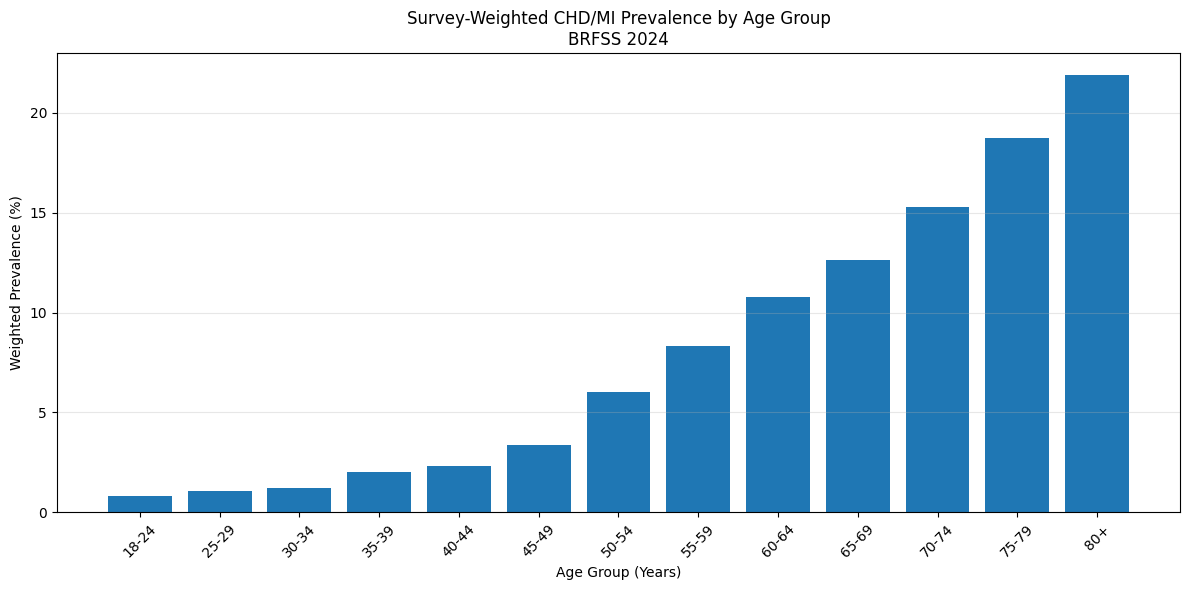


SUCCESS: EDA Part 1 completed.

Results saved to: /content/drive/MyDrive/QM640_Capstone/outputs
Charts saved to: /content/drive/MyDrive/QM640_Capstone/figures


In [6]:
# ============================================================
# QM640 CAPSTONE - STEP 5
# EXPLORATORY DATA ANALYSIS - PART 1
# RQ1: CHD/MI Prevalence by Age and Sex
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

print("=" * 65)
print("BRFSS 2024 - EDA PART 1")
print("=" * 65)

# Load cleaned dataset from Google Drive
clean_path = (
    "/content/drive/MyDrive/QM640_Capstone/data/"
    "BRFSS_2024_cleaned.parquet"
)

df_eda = pd.read_parquet(clean_path)

# Create output folders
base_folder = "/content/drive/MyDrive/QM640_Capstone"

output_folder = base_folder + "/outputs"
figure_folder = base_folder + "/figures"

os.makedirs(output_folder, exist_ok=True)
os.makedirs(figure_folder, exist_ok=True)

# ------------------------------------------------------------
# 1. Overall prevalence
# ------------------------------------------------------------

print("\n1. OVERALL CHD/MI PREVALENCE")

unweighted_prevalence = (
    df_eda["heart_disease"].mean() * 100
)

weighted_prevalence = (
    np.average(
        df_eda["heart_disease"],
        weights=df_eda["_LLCPWT"]
    ) * 100
)

print(
    "Unweighted prevalence:",
    round(unweighted_prevalence, 2), "%"
)

print(
    "Survey-weighted prevalence:",
    round(weighted_prevalence, 2), "%"
)

# ------------------------------------------------------------
# 2. Weighted prevalence calculation
# ------------------------------------------------------------

def weighted_prevalence_by_group(data, group_column):

    valid_data = data.dropna(
        subset=[
            group_column,
            "heart_disease",
            "_LLCPWT"
        ]
    ).copy()

    results = []

    for group, subset in valid_data.groupby(group_column):

        prevalence = np.average(
            subset["heart_disease"],
            weights=subset["_LLCPWT"]
        ) * 100

        results.append({
            "Group": group,
            "Sample_Size": len(subset),
            "Positive_Cases": int(
                subset["heart_disease"].sum()
            ),
            "Weighted_Prevalence_Percent": round(
                prevalence, 2
            )
        })

    return pd.DataFrame(results)

# ------------------------------------------------------------
# 3. Prevalence by sex
# ------------------------------------------------------------

print("\n2. CHD/MI PREVALENCE BY SEX")

sex_prevalence = weighted_prevalence_by_group(
    df_eda,
    "_SEX"
)

sex_prevalence["Sex"] = (
    sex_prevalence["Group"].map({
        1: "Male",
        2: "Female"
    })
)

display(sex_prevalence)

sex_prevalence.to_csv(
    output_folder + "/RQ1_prevalence_by_sex.csv",
    index=False
)

# ------------------------------------------------------------
# 4. Prevalence by age group
# ------------------------------------------------------------

print("\n3. CHD/MI PREVALENCE BY AGE GROUP")

age_prevalence = weighted_prevalence_by_group(
    df_eda,
    "_AGEG5YR"
)

age_labels = {
    1: "18-24",
    2: "25-29",
    3: "30-34",
    4: "35-39",
    5: "40-44",
    6: "45-49",
    7: "50-54",
    8: "55-59",
    9: "60-64",
    10: "65-69",
    11: "70-74",
    12: "75-79",
    13: "80+"
}

age_prevalence["Age_Group"] = (
    age_prevalence["Group"].map(age_labels)
)

display(age_prevalence)

age_prevalence.to_csv(
    output_folder + "/RQ1_prevalence_by_age.csv",
    index=False
)

# ------------------------------------------------------------
# 5. Age group prevalence chart
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.bar(
    age_prevalence["Age_Group"],
    age_prevalence["Weighted_Prevalence_Percent"]
)

plt.title(
    "Survey-Weighted CHD/MI Prevalence by Age Group\n"
    "BRFSS 2024"
)

plt.xlabel("Age Group (Years)")
plt.ylabel("Weighted Prevalence (%)")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    figure_folder + "/RQ1_age_prevalence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 6. Save overall prevalence
# ------------------------------------------------------------

overall_results = pd.DataFrame({
    "Metric": [
        "Original Sample Size",
        "Eligible Sample Size",
        "Positive CHD/MI Cases",
        "Unweighted Prevalence (%)",
        "Survey-Weighted Prevalence (%)"
    ],
    "Value": [
        457670,
        len(df_eda),
        int(df_eda["heart_disease"].sum()),
        round(unweighted_prevalence, 2),
        round(weighted_prevalence, 2)
    ]
})

overall_results.to_csv(
    output_folder + "/RQ1_overall_prevalence.csv",
    index=False
)

print("\nSUCCESS: EDA Part 1 completed.")

print("\nResults saved to:", output_folder)
print("Charts saved to:", figure_folder)

BRFSS 2024 - EDA PART 2

SMOKING STATUS


,Category_Code,Category,Sample_Size,Positive_Cases,Weighted_Prevalence_Percent
0,1.0,Current Daily,32628,4372,10.78
1,2.0,Current Occasional,13776,1497,8.17
2,3.0,Former,118181,16647,11.43
3,4.0,Never,256497,17071,4.64


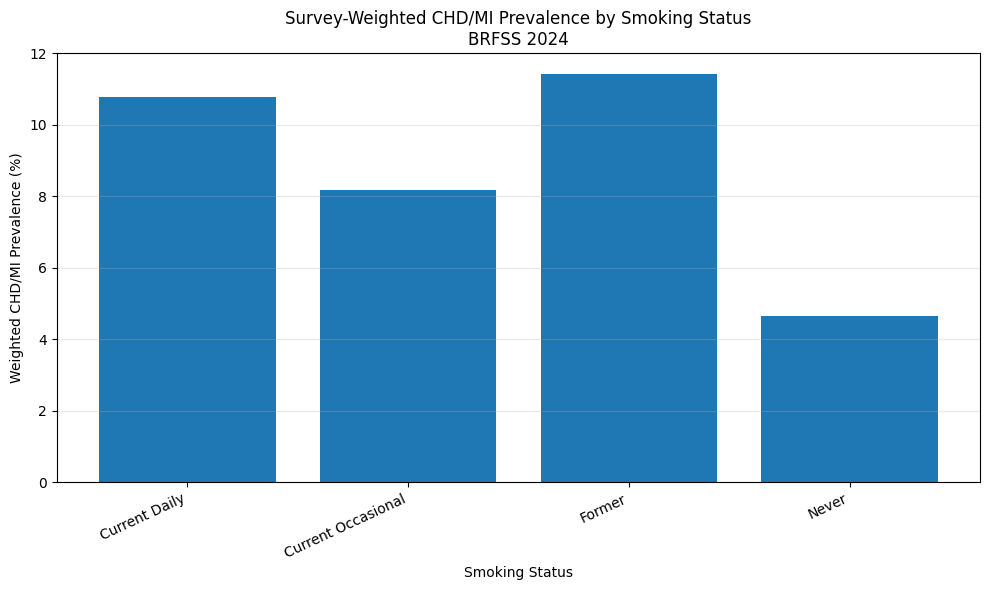


PHYSICAL ACTIVITY


,Category_Code,Category,Sample_Size,Positive_Cases,Weighted_Prevalence_Percent
0,1.0,Active,346912,27003,5.62
1,2.0,Inactive,104358,15166,10.77


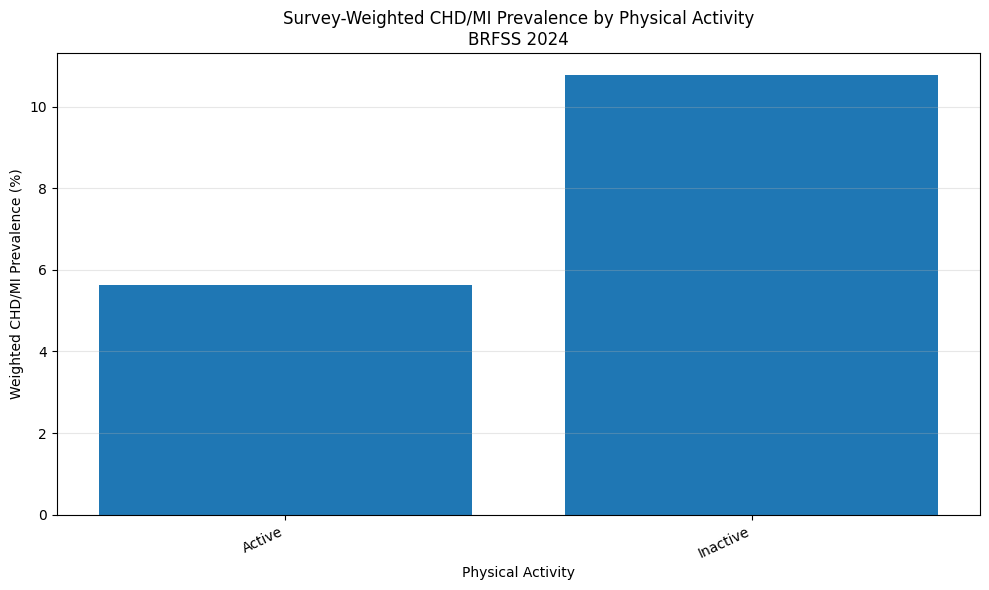


BMI CATEGORY


,Category_Code,Category,Sample_Size,Positive_Cases,Weighted_Prevalence_Percent
0,1.0,Underweight,7259,666,6.20
1,2.0,Normal,119864,9440,5.43
2,3.0,Overweight,145112,14309,7.38
3,4.0,Obese,138046,15015,8.13


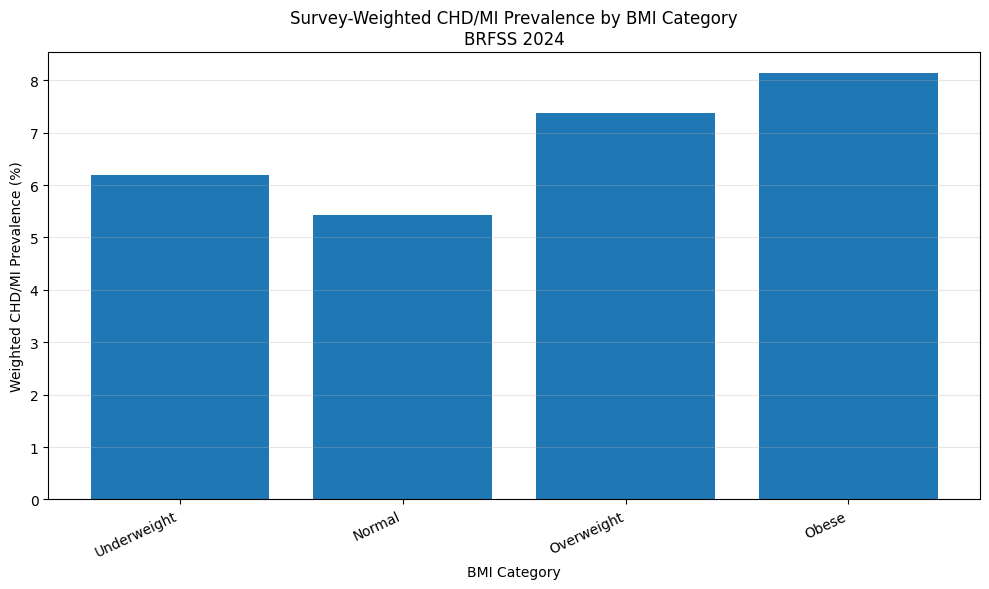


DIABETES STATUS


,Category_Code,Category,Sample_Size,Positive_Cases,Weighted_Prevalence_Percent
0,1.0,Diabetes,64586,14217,18.86
1,2.0,During Pregnancy,3365,182,4.72
2,3.0,No Diabetes,372683,26375,4.92
3,4.0,Prediabetes,11059,1480,11.03


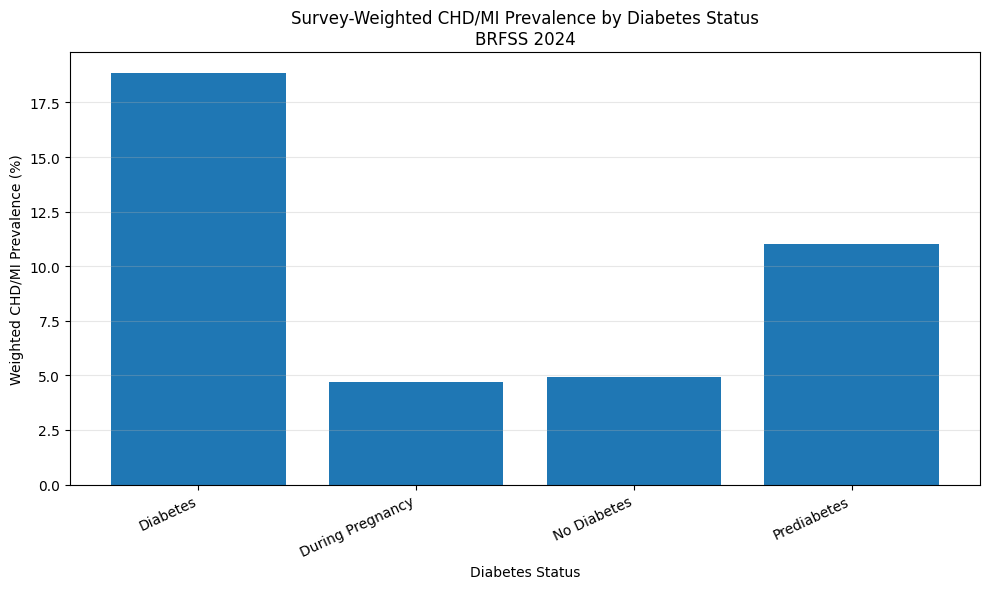


SUCCESS: EDA Part 2 completed.
CSV results: /content/drive/MyDrive/QM640_Capstone/outputs
Figures: /content/drive/MyDrive/QM640_Capstone/figures


In [7]:
# ============================================================
# QM640 CAPSTONE - STEP 6
# EDA PART 2: BEHAVIORAL AND HEALTH RISK FACTORS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

print("=" * 65)
print("BRFSS 2024 - EDA PART 2")
print("=" * 65)

# Load cleaned dataset
base_folder = "/content/drive/MyDrive/QM640_Capstone"

df_eda = pd.read_parquet(
    base_folder + "/data/BRFSS_2024_cleaned.parquet"
)

output_folder = base_folder + "/outputs"
figure_folder = base_folder + "/figures"

os.makedirs(output_folder, exist_ok=True)
os.makedirs(figure_folder, exist_ok=True)

# ------------------------------------------------------------
# 1. Define risk factor categories
# ------------------------------------------------------------

risk_factors = {
    "_SMOKER3": {
        "title": "Smoking Status",
        "labels": {
            1: "Current Daily",
            2: "Current Occasional",
            3: "Former",
            4: "Never"
        }
    },

    "_TOTINDA": {
        "title": "Physical Activity",
        "labels": {
            1: "Active",
            2: "Inactive"
        }
    },

    "BMI_category": {
        "title": "BMI Category",
        "labels": {
            1: "Underweight",
            2: "Normal",
            3: "Overweight",
            4: "Obese"
        }
    },

    "DIABETE4": {
        "title": "Diabetes Status",
        "labels": {
            1: "Diabetes",
            2: "During Pregnancy",
            3: "No Diabetes",
            4: "Prediabetes"
        }
    }
}

# ------------------------------------------------------------
# 2. Weighted prevalence function
# ------------------------------------------------------------

def calculate_weighted_prevalence(data, column, labels):

    valid = data.dropna(
        subset=[
            column,
            "heart_disease",
            "_LLCPWT"
        ]
    ).copy()

    results = []

    for category, subset in valid.groupby(column):

        weighted_prev = np.average(
            subset["heart_disease"],
            weights=subset["_LLCPWT"]
        ) * 100

        results.append({
            "Category_Code": category,
            "Category": labels.get(
                category,
                str(category)
            ),
            "Sample_Size": len(subset),
            "Positive_Cases": int(
                subset["heart_disease"].sum()
            ),
            "Weighted_Prevalence_Percent": round(
                weighted_prev, 2
            )
        })

    return pd.DataFrame(results)

# ------------------------------------------------------------
# 3. Analyze each risk factor
# ------------------------------------------------------------

for variable, details in risk_factors.items():

    print("\n" + "=" * 55)
    print(details["title"].upper())
    print("=" * 55)

    result = calculate_weighted_prevalence(
        df_eda,
        variable,
        details["labels"]
    )

    display(result)

    # Save CSV
    filename = (
        variable.replace("_", "") +
        "_weighted_prevalence.csv"
    )

    result.to_csv(
        output_folder + "/" + filename,
        index=False
    )

    # --------------------------------------------------------
    # 4. Generate chart
    # --------------------------------------------------------

    plt.figure(figsize=(10, 6))

    plt.bar(
        result["Category"],
        result["Weighted_Prevalence_Percent"]
    )

    plt.title(
        "Survey-Weighted CHD/MI Prevalence by " +
        details["title"] +
        "\nBRFSS 2024"
    )

    plt.xlabel(details["title"])
    plt.ylabel("Weighted CHD/MI Prevalence (%)")

    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()

    chart_name = (
        variable.replace("_", "") +
        "_prevalence.png"
    )

    plt.savefig(
        figure_folder + "/" + chart_name,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("\nSUCCESS: EDA Part 2 completed.")
print("CSV results:", output_folder)
print("Figures:", figure_folder)

In [8]:
# ============================================================
# QM640 CAPSTONE - STEP 7A
# VERIFY COMPLEX SURVEY DESIGN STRUCTURE
# ============================================================

import pandas as pd
import numpy as np
import os

base_folder = "/content/drive/MyDrive/QM640_Capstone"

df_survey = pd.read_parquet(
    base_folder + "/data/BRFSS_2024_cleaned.parquet"
)

print("=" * 65)
print("BRFSS 2024 - SURVEY DESIGN VERIFICATION")
print("=" * 65)

# 1. Survey design variable availability
design_variables = ["_LLCPWT", "_STSTR", "_PSU"]

print("\n1. SURVEY DESIGN VARIABLES")

for col in design_variables:
    print(
        col,
        "| Available:", col in df_survey.columns,
        "| Missing:", df_survey[col].isna().sum()
    )

# 2. Weight distribution
print("\n2. SURVEY WEIGHT SUMMARY")

display(df_survey["_LLCPWT"].describe())

# 3. Number of strata and PSUs
print("\n3. SURVEY DESIGN STRUCTURE")

print(
    "Unique strata:",
    df_survey["_STSTR"].nunique()
)

print(
    "Unique PSU identifiers:",
    df_survey["_PSU"].nunique()
)

# 4. PSU counts within each stratum
print("\n4. PSU COUNTS WITHIN STRATA")

psu_counts = (
    df_survey.groupby("_STSTR")["_PSU"]
    .nunique()
)

display(psu_counts.describe())

print(
    "Strata with only one PSU:",
    int((psu_counts == 1).sum())
)

# 5. Save survey design verification
output_folder = base_folder + "/outputs"

os.makedirs(output_folder, exist_ok=True)

survey_summary = pd.DataFrame({
    "Metric": [
        "Eligible respondents",
        "Unique strata",
        "Unique PSU identifiers",
        "Strata with one PSU",
        "Minimum survey weight",
        "Maximum survey weight"
    ],
    "Value": [
        len(df_survey),
        df_survey["_STSTR"].nunique(),
        df_survey["_PSU"].nunique(),
        int((psu_counts == 1).sum()),
        df_survey["_LLCPWT"].min(),
        df_survey["_LLCPWT"].max()
    ]
})

survey_summary.to_csv(
    output_folder + "/survey_design_verification.csv",
    index=False
)

print("\nSUCCESS: Survey design verification completed.")
print("Results saved to:", output_folder)

BRFSS 2024 - SURVEY DESIGN VERIFICATION

1. SURVEY DESIGN VARIABLES
_LLCPWT | Available: True | Missing: 0
_STSTR | Available: True | Missing: 0
_PSU | Available: True | Missing: 0

2. SURVEY WEIGHT SUMMARY


,_LLCPWT
count,452464.000000
mean,576.425325
std,1170.632622
min,0.012286
25%,106.743783
50%,263.939952
75%,581.875843
max,49582.191041



3. SURVEY DESIGN STRUCTURE
Unique strata: 2393
Unique PSU identifiers: 43691

4. PSU COUNTS WITHIN STRATA


,_PSU
count,2393.000000
mean,189.078145
std,370.897029
min,1.000000
25%,12.000000
50%,86.000000
75%,212.000000
max,5408.000000


Strata with only one PSU: 111

SUCCESS: Survey design verification completed.
Results saved to: /content/drive/MyDrive/QM640_Capstone/outputs


In [9]:
# ============================================================
# QM640 CAPSTONE - STEP 7B
# SURVEY DESIGN DIAGNOSTICS
# ============================================================

import pandas as pd

print("=" * 65)
print("BRFSS 2024 - PSU AND STRATUM DIAGNOSTICS")
print("=" * 65)

# Use existing cleaned dataset
df_design = df_clean.copy()

# 1. Number of observations per PSU
print("\n1. OBSERVATIONS PER PSU")

psu_sizes = (
    df_design.groupby("_PSU")
    .size()
)

display(psu_sizes.describe())

print(
    "PSUs with one observation:",
    int((psu_sizes == 1).sum())
)

# 2. Check whether PSU IDs occur in multiple strata
print("\n2. PSU IDENTIFIERS ACROSS STRATA")

psu_strata = (
    df_design.groupby("_PSU")["_STSTR"]
    .nunique()
)

print(
    "PSU identifiers appearing in multiple strata:",
    int((psu_strata > 1).sum())
)

# 3. Unique PSU-stratum combinations
print("\n3. UNIQUE PSU-STRATUM COMBINATIONS")

unique_combinations = (
    df_design[["_STSTR", "_PSU"]]
    .drop_duplicates()
)

print(
    "Unique combinations:",
    len(unique_combinations)
)

# 4. Sample design records
print("\n4. SAMPLE SURVEY DESIGN RECORDS")

display(
    df_design[
        ["_STATE", "_STSTR", "_PSU", "_LLCPWT"]
    ].head(15)
)

print("\nSTEP 7B COMPLETED")

BRFSS 2024 - PSU AND STRATUM DIAGNOSTICS

1. OBSERVATIONS PER PSU


,0
count,43691.000000
mean,10.356000
std,16.000923
min,1.000000
25%,1.000000
50%,2.000000
75%,13.000000
max,53.000000


PSUs with one observation: 18126

2. PSU IDENTIFIERS ACROSS STRATA
PSU identifiers appearing in multiple strata: 25565

3. UNIQUE PSU-STRATUM COMBINATIONS
Unique combinations: 452464

4. SAMPLE SURVEY DESIGN RECORDS


,_STATE,_STSTR,_PSU,_LLCPWT
0,1.0,11011.0,2.024000e+09,261.525511
1,1.0,11011.0,2.024000e+09,307.169688
2,1.0,11011.0,2.024000e+09,2939.862806
3,1.0,11011.0,2.024000e+09,153.584844
4,1.0,11011.0,2.024000e+09,1229.623036
5,1.0,11011.0,2.024000e+09,451.219871
6,1.0,11011.0,2.024000e+09,388.467984
7,1.0,11011.0,2.024000e+09,194.233992
8,1.0,11011.0,2.024000e+09,455.584194
9,1.0,11011.0,2.024000e+09,211.232063



STEP 7B COMPLETED


In [10]:
# ============================================================
# QM640 CAPSTONE - STEP 7C
# VERIFY SURVEY DESIGN IDENTIFIERS
# ============================================================

import pandas as pd

print("=" * 65)
print("BRFSS 2024 - SURVEY IDENTIFIER VERIFICATION")
print("=" * 65)

# Load cleaned dataset
df_check = pd.read_parquet(
    "/content/drive/MyDrive/QM640_Capstone/data/"
    "BRFSS_2024_cleaned.parquet"
)

# 1. Identify potentially relevant design columns
print("\n1. AVAILABLE SURVEY-RELATED COLUMNS")

keywords = [
    "PSU",
    "STSTR",
    "STRATA",
    "WEIGHT",
    "LLCP",
    "SEQNO",
    "CLUSTER"
]

matching_columns = [
    col for col in df_check.columns
    if any(
        keyword in col.upper()
        for keyword in keywords
    )
]

print(matching_columns)

# 2. Inspect data types
print("\n2. SURVEY VARIABLE DATA TYPES")

display(
    df_check[
        ["_STSTR", "_PSU", "_LLCPWT"]
    ].dtypes
)

# 3. Verify unique PSU-stratum combinations
print("\n3. IDENTIFIER UNIQUENESS")

print(
    "Total records:",
    len(df_check)
)

print(
    "Unique stratum-PSU combinations:",
    df_check[
        ["_STSTR", "_PSU"]
    ].drop_duplicates().shape[0]
)

# 4. Examine identifiers without scientific notation
print("\n4. SAMPLE IDENTIFIER VALUES")

sample = df_check[
    ["_STATE", "_STSTR", "_PSU", "_LLCPWT"]
].head(20).copy()

pd.set_option("display.float_format", "{:.6f}".format)

display(sample)

print("\nSTEP 7C COMPLETED")

BRFSS 2024 - SURVEY IDENTIFIER VERIFICATION

1. AVAILABLE SURVEY-RELATED COLUMNS
['SEQNO', '_PSU', 'WEIGHT2', '_STSTR', '_CLLCPWT', '_LLCPWT2', '_LLCPWT']

2. SURVEY VARIABLE DATA TYPES


,0
_STSTR,float64
_PSU,float64
_LLCPWT,float64



3. IDENTIFIER UNIQUENESS
Total records: 452464
Unique stratum-PSU combinations: 452464

4. SAMPLE IDENTIFIER VALUES


,_STATE,_STSTR,_PSU,_LLCPWT
0,1.000000,11011.000000,2024000001.000000,261.525511
1,1.000000,11011.000000,2024000002.000000,307.169688
2,1.000000,11011.000000,2024000003.000000,2939.862806
3,1.000000,11011.000000,2024000004.000000,153.584844
4,1.000000,11011.000000,2024000005.000000,1229.623036
5,1.000000,11011.000000,2024000006.000000,451.219871
6,1.000000,11011.000000,2024000007.000000,388.467984
7,1.000000,11011.000000,2024000008.000000,194.233992
8,1.000000,11011.000000,2024000009.000000,455.584194
9,1.000000,11011.000000,2024000010.000000,211.232063



STEP 7C COMPLETED


In [11]:
# ============================================================
# QM640 CAPSTONE - STEP 8
# PREPARE DATA FOR SURVEY-ADJUSTED ANALYSIS
# ============================================================

import pandas as pd
import os

print("=" * 65)
print("BRFSS 2024 - SURVEY ANALYSIS DATA PREPARATION")
print("=" * 65)

base_folder = "/content/drive/MyDrive/QM640_Capstone"

df_analysis = pd.read_parquet(
    base_folder + "/data/BRFSS_2024_cleaned.parquet"
)

# Variables needed for statistical analysis
survey_columns = [
    "heart_disease",
    "_AGEG5YR",
    "_SEX",
    "_RACEGR3",
    "_EDUCAG",
    "_INCOMG1",
    "BMI",
    "BMI_category",
    "_SMOKER3",
    "_TOTINDA",
    "DIABETE4",
    "GENHLTH",
    "mental_health_days",
    "_LLCPWT",
    "_STSTR",
    "_PSU"
]

# Create separate analysis dataset
survey_df = df_analysis[survey_columns].copy()

print("\nAnalysis dataset dimensions:")
print(survey_df.shape)

print("\nMissing values:")
display(survey_df.isna().sum().to_frame("Missing_Count"))

# Save analysis-ready data
analysis_folder = base_folder + "/analysis"

os.makedirs(analysis_folder, exist_ok=True)

analysis_path = (
    analysis_folder + "/BRFSS_2024_survey_analysis.csv"
)

survey_df.to_csv(
    analysis_path,
    index=False
)

print("\nSUCCESS: Survey analysis dataset saved.")
print("Location:", analysis_path)

print(
    "File size (MB):",
    round(
        os.path.getsize(analysis_path) / 1024**2,
        2
    )
)

print("\nSTEP 8 COMPLETED")

BRFSS 2024 - SURVEY ANALYSIS DATA PREPARATION

Analysis dataset dimensions:
(452464, 16)

Missing values:


,Missing_Count
heart_disease,0
_AGEG5YR,8023
_SEX,0
_RACEGR3,8778
_EDUCAG,2199
_INCOMG1,85558
BMI,42183
BMI_category,42183
_SMOKER3,31382
_TOTINDA,1194



SUCCESS: Survey analysis dataset saved.
Location: /content/drive/MyDrive/QM640_Capstone/analysis/BRFSS_2024_survey_analysis.csv
File size (MB): 39.26

STEP 8 COMPLETED


In [12]:
# ============================================================
# QM640 CAPSTONE - STEP 9A
# INSTALL R AND SURVEY ANALYSIS PACKAGES
# ============================================================

import subprocess

print("Installing R and survey analysis packages...")

subprocess.run(
    ["apt-get", "update", "-qq"],
    check=True
)

subprocess.run(
    [
        "apt-get",
        "install",
        "-y",
        "-qq",
        "r-base",
        "r-cran-survey"
    ],
    check=True
)

print("SUCCESS: R and survey package installed.")

Installing R and survey analysis packages...
SUCCESS: R and survey package installed.


In [13]:
# ============================================================
# QM640 CAPSTONE - STEP 9B
# RQ1: SURVEY-ADJUSTED PREVALENCE AND ASSOCIATION TESTS
# ============================================================

import subprocess
import os

base_folder = "/content/drive/MyDrive/QM640_Capstone"
output_folder = base_folder + "/outputs"

os.makedirs(output_folder, exist_ok=True)

r_script = r'''
library(survey)

options(survey.lonely.psu = "adjust")

base_path <- "/content/drive/MyDrive/QM640_Capstone"

input_file <- file.path(
  base_path,
  "analysis",
  "BRFSS_2024_survey_analysis.csv"
)

output_path <- file.path(base_path, "outputs")

cat("============================================\n")
cat("RQ1: SURVEY-ADJUSTED ANALYSIS\n")
cat("============================================\n")

# Read dataset
df <- read.csv(input_file, check.names = FALSE)

cat("\nRecords loaded:", nrow(df), "\n")

# Rename columns for R convenience
names(df) <- sub("^_", "", names(df))

# Prepare outcome
df$heart_disease <- as.numeric(df$heart_disease)

# Define survey design
design <- svydesign(
  ids = ~PSU,
  strata = ~STSTR,
  weights = ~LLCPWT,
  data = df,
  nest = TRUE
)

cat("\nSurvey design created successfully.\n")

# ---------------------------------------------------------
# 1. Overall weighted prevalence
# ---------------------------------------------------------

cat("\n1. OVERALL WEIGHTED PREVALENCE\n")

overall <- svymean(
  ~heart_disease,
  design,
  na.rm = TRUE
)

overall_result <- data.frame(
  Group = "Overall",
  Prevalence_Percent = as.numeric(coef(overall)) * 100,
  SE_Percent = as.numeric(SE(overall)) * 100,
  CI_Lower = confint(overall)[1] * 100,
  CI_Upper = confint(overall)[2] * 100
)

print(overall_result)

write.csv(
  overall_result,
  file.path(output_path, "RQ1_overall_survey_adjusted.csv"),
  row.names = FALSE
)

# ---------------------------------------------------------
# 2. Sex-specific prevalence
# ---------------------------------------------------------

cat("\n2. PREVALENCE BY SEX\n")

sex_design <- subset(design, !is.na(SEX))

sex_results <- svyby(
  ~heart_disease,
  ~SEX,
  sex_design,
  svymean,
  na.rm = TRUE,
  vartype = c("se", "ci")
)

sex_results$Sex_Label <- ifelse(
  sex_results$SEX == 1,
  "Male",
  "Female"
)

print(sex_results)

write.csv(
  sex_results,
  file.path(output_path, "RQ1_sex_survey_adjusted.csv"),
  row.names = FALSE
)

# ---------------------------------------------------------
# 3. Age-specific prevalence
# ---------------------------------------------------------

cat("\n3. PREVALENCE BY AGE GROUP\n")

age_design <- subset(design, !is.na(AGEG5YR))

age_results <- svyby(
  ~heart_disease,
  ~AGEG5YR,
  age_design,
  svymean,
  na.rm = TRUE,
  vartype = c("se", "ci")
)

print(age_results)

write.csv(
  age_results,
  file.path(output_path, "RQ1_age_survey_adjusted.csv"),
  row.names = FALSE
)

# ---------------------------------------------------------
# 4. Survey-adjusted association: Sex
# ---------------------------------------------------------

cat("\n4. SEX ASSOCIATION TEST\n")

sex_test <- svychisq(
  ~factor(SEX) + factor(heart_disease),
  sex_design,
  statistic = "F"
)

print(sex_test)

# ---------------------------------------------------------
# 5. Survey-adjusted association: Age
# ---------------------------------------------------------

cat("\n5. AGE ASSOCIATION TEST\n")

age_test <- svychisq(
  ~factor(AGEG5YR) + factor(heart_disease),
  age_design,
  statistic = "F"
)

print(age_test)

# ---------------------------------------------------------
# 6. Save statistical test results
# ---------------------------------------------------------

test_results <- data.frame(
  Research_Question = c("RQ1", "RQ1"),
  Comparison = c("Sex", "Age Group"),
  Test = c(
    "Survey-adjusted Rao-Scott F",
    "Survey-adjusted Rao-Scott F"
  ),
  F_Statistic = c(
    as.numeric(sex_test$statistic),
    as.numeric(age_test$statistic)
  ),
  P_Value = c(
    sex_test$p.value,
    age_test$p.value
  )
)

write.csv(
  test_results,
  file.path(output_path, "RQ1_statistical_tests.csv"),
  row.names = FALSE
)

cat("\n============================================\n")
cat("RQ1 ANALYSIS COMPLETED SUCCESSFULLY\n")
cat("============================================\n")
'''

script_path = "/content/QM640_RQ1_survey_analysis.R"

with open(script_path, "w") as f:
    f.write(r_script)

result = subprocess.run(
    ["Rscript", script_path],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print("R ERROR:")
    print(result.stderr)
    raise RuntimeError("RQ1 survey analysis failed.")

print("\nSUCCESS: RQ1 survey-adjusted analysis completed.")

KeyboardInterrupt: 

In [14]:
# ============================================================
# QM640 CAPSTONE - STEP 9B CONTINUATION
# RQ1: RESUMABLE AGE-GROUP SURVEY ANALYSIS
# ============================================================

import os
import subprocess

base_folder = "/content/drive/MyDrive/QM640_Capstone"
output_folder = base_folder + "/outputs"

os.makedirs(output_folder, exist_ok=True)

r_script = r'''
library(survey)

options(survey.lonely.psu = "adjust")

base_path <- "/content/drive/MyDrive/QM640_Capstone"

input_file <- file.path(
    base_path,
    "analysis",
    "BRFSS_2024_survey_analysis.csv"
)

output_file <- file.path(
    base_path,
    "outputs",
    "RQ1_age_survey_adjusted.csv"
)

cat("Loading BRFSS dataset...\n")

df <- read.csv(
    input_file,
    check.names = FALSE
)

names(df) <- sub("^_", "", names(df))

df$heart_disease <- as.numeric(df$heart_disease)

cat("Records:", nrow(df), "\n")

# ------------------------------------------------------------
# Create survey design ONCE
# ------------------------------------------------------------

design <- svydesign(
    ids = ~PSU,
    strata = ~STSTR,
    weights = ~LLCPWT,
    data = df,
    nest = TRUE
)

cat("Survey design created.\n")

# ------------------------------------------------------------
# Resume previously completed age groups
# ------------------------------------------------------------

if (file.exists(output_file)) {

    results <- read.csv(output_file)

    completed <- results$Age_Code

    cat("Previously completed:", completed, "\n")

} else {

    results <- data.frame(
        Age_Code = numeric(),
        Sample_Size = numeric(),
        Prevalence_Percent = numeric(),
        CI_Lower = numeric(),
        CI_Upper = numeric()
    )

    completed <- numeric()
}

age_codes <- sort(unique(na.omit(df$AGEG5YR)))

# ------------------------------------------------------------
# Process one age group at a time
# ------------------------------------------------------------

for (age in age_codes) {

    if (age %in% completed) {
        next
    }

    cat("\nProcessing age code:", age, "\n")

    age_design <- subset(
        design,
        AGEG5YR == age
    )

    estimate <- svymean(
        ~heart_disease,
        age_design,
        na.rm = TRUE
    )

    ci <- confint(estimate)

    new_row <- data.frame(
        Age_Code = age,
        Sample_Size = sum(df$AGEG5YR == age, na.rm = TRUE),
        Prevalence_Percent = as.numeric(coef(estimate)) * 100,
        CI_Lower = as.numeric(ci[1]) * 100,
        CI_Upper = as.numeric(ci[2]) * 100
    )

    results <- rbind(results, new_row)

    write.csv(
        results,
        output_file,
        row.names = FALSE
    )

    cat(
        "Saved:",
        round(new_row$Prevalence_Percent, 2),
        "%\n"
    )

    flush.console()
}

cat("\nRQ1 AGE ANALYSIS COMPLETED.\n")

print(results)
'''

script_path = "/content/QM640_RQ1_age_resume.R"

with open(script_path, "w") as f:
    f.write(r_script)

# Stream output so progress is visible immediately
with subprocess.Popen(
    ["Rscript", "--vanilla", script_path],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
) as process:

    for line in process.stdout:
        print(line, end="", flush=True)

    return_code = process.wait()

if return_code != 0:
    raise RuntimeError(
        f"R analysis failed with exit code {return_code}"
    )

print("\nSUCCESS: RQ1 age-group analysis completed.")

Loading required package: grid
Loading required package: Matrix
Loading required package: survival

Attaching package: ‘survey’

The following object is masked from ‘package:graphics’:

    dotchart

Loading BRFSS dataset...
Records: 452464 
Survey design created.

Processing age code: 1 
Saved: 0.82 %

Processing age code: 2 
Saved: 1.06 %

Processing age code: 3 
Saved: 1.22 %

Processing age code: 4 
Saved: 2.01 %

Processing age code: 5 
Saved: 2.33 %

Processing age code: 6 
Saved: 3.37 %

Processing age code: 7 
Saved: 6.02 %

Processing age code: 8 
Saved: 8.31 %

Processing age code: 9 
Saved: 10.77 %

Processing age code: 10 
Saved: 12.61 %

Processing age code: 11 
Saved: 15.29 %

Processing age code: 12 
Saved: 18.75 %

Processing age code: 13 
Saved: 21.89 %

RQ1 AGE ANALYSIS COMPLETED.
   Age_Code Sample_Size Prevalence_Percent   CI_Lower  CI_Upper
1         1       29455          0.8195272  0.6400033  0.999051
2         2       23542          1.0587089  0.7979950  1.31942

QM640 CAPSTONE - REMAINING PRELIMINARY ANALYSIS

Dataset loaded: (452464, 305)

RQ2: PRELIMINARY ASSOCIATION TESTS


,Risk_Factor,Sample_Size,Chi_Square,Degrees_of_Freedom,P_Value,Minimum_Expected_Count,Analysis_Type
0,Smoking Status,421082,5962.799863,3,0.000000,1295.117132,Unweighted exploratory Pearson chi-square
1,Physical Activity,451270,4312.576080,1,0.000000,9751.750619,Unweighted exploratory Pearson chi-square
2,BMI Category,410281,682.179162,3,0.000000,697.625213,Unweighted exploratory Pearson chi-square
3,Diabetes Status,451693,14756.952715,3,0.000000,314.781743,Unweighted exploratory Pearson chi-square



RQ2 preliminary association tests saved.

PREPARING MODELING DATA
Preliminary modeling sample: 60000
Training records: 48000
Testing records: 12000
Positive test cases: 1123
Processed feature count: 41

RQ3: PRELIMINARY MULTIVARIABLE LOGISTIC REGRESSION

RQ3 results saved.


,Feature,Coefficient,Adjusted_Odds_Ratio,CI_Lower_95,CI_Upper_95
3,categorical___AGEG5YR_13,2.789171,16.267536,11.944623,22.154965
2,categorical___AGEG5YR_12,2.460852,11.714784,8.577097,16.000304
1,categorical___AGEG5YR_11,2.297233,9.946621,7.295114,13.561854
39,categorical__GENHLTH_5,2.203473,9.056408,7.440839,11.022751
0,categorical___AGEG5YR_10,1.871235,6.496312,4.764971,8.856732
11,categorical___AGEG5YR_9,1.749467,5.751534,4.205051,7.866764
38,categorical__GENHLTH_4,1.679704,5.363969,4.493055,6.403697
10,categorical___AGEG5YR_8,1.435289,4.200858,3.044458,5.796503
9,categorical___AGEG5YR_7,1.136451,3.115691,2.236245,4.340995
37,categorical__GENHLTH_3,1.127962,3.089353,2.606972,3.660992



RQ4: MACHINE-LEARNING MODEL COMPARISON

Training: Logistic Regression
AUROC=0.8236, AUPRC=0.3182, Recall=0.7943, Precision=0.2246

Training: Decision Tree
AUROC=0.7637, AUPRC=0.2626, Recall=0.6518, Precision=0.2168

Training: Random Forest
AUROC=0.8091, AUPRC=0.3114, Recall=0.7640, Precision=0.2230

Training: Gradient Boosting
AUROC=0.8211, AUPRC=0.3233, Recall=0.0258, Precision=0.5370

FINAL MODEL COMPARISON


,Model,Accuracy,AUROC,AUPRC,Precision,Recall,F1,Brier_Score,Recall_Target_Met,Precision_Target_Met
0,Logistic Regression,0.724200,0.823600,0.318200,0.224600,0.794300,0.350200,0.179200,False,True
1,Decision Tree,0.747000,0.763700,0.262600,0.216800,0.651800,0.325300,0.194500,False,True
2,Random Forest,0.728800,0.809100,0.311400,0.223000,0.764000,0.345300,0.181400,False,True
3,Gradient Boosting,0.906800,0.821100,0.323300,0.537000,0.025800,0.049300,0.072700,False,True


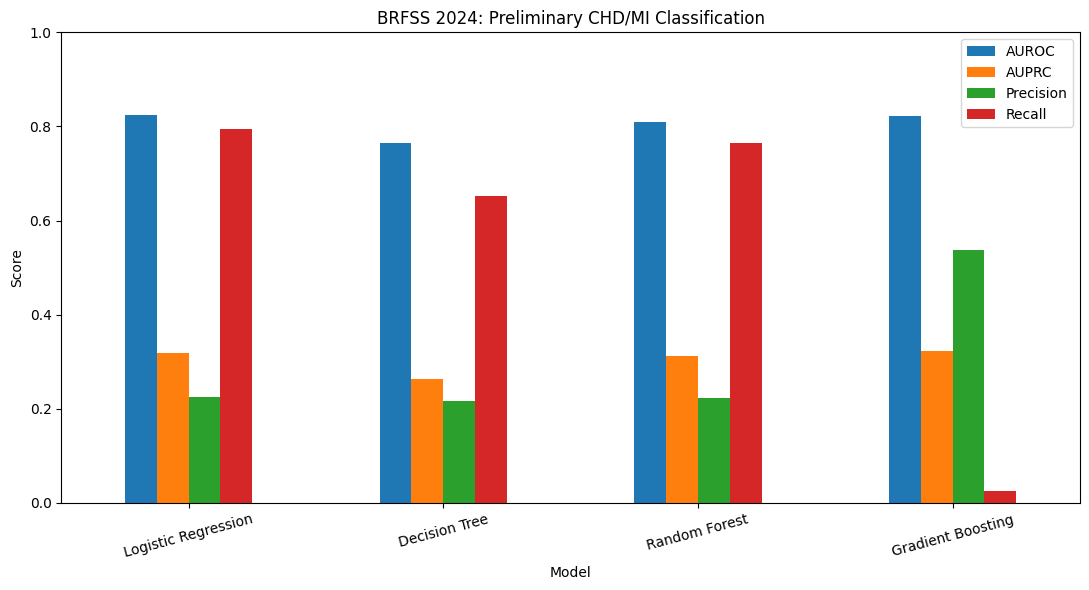


SUCCESS: RQ2, RQ3 AND RQ4 PRELIMINARY ANALYSES COMPLETED
Total runtime: 14.6 seconds
Results saved: /content/drive/MyDrive/QM640_Capstone/outputs
Figures saved: /content/drive/MyDrive/QM640_Capstone/figures


In [15]:
# ============================================================
# QM640 CAPSTONE - STEP 10
# FAST RQ2 + RQ3 + RQ4 PRELIMINARY ANALYSIS
# ============================================================

import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss
)

warnings.filterwarnings("ignore", category=FutureWarning)

START = time.time()

BASE = "/content/drive/MyDrive/QM640_Capstone"
OUT = BASE + "/outputs"
FIG = BASE + "/figures"

os.makedirs(OUT, exist_ok=True)
os.makedirs(FIG, exist_ok=True)

print("=" * 65)
print("QM640 CAPSTONE - REMAINING PRELIMINARY ANALYSIS")
print("=" * 65)

# ============================================================
# PART 1: LOAD EXISTING CLEANED DATA
# ============================================================

df = pd.read_parquet(
    BASE + "/data/BRFSS_2024_cleaned.parquet"
)

print("\nDataset loaded:", df.shape)

# ============================================================
# PART 2: RQ2 ASSOCIATION TESTS
# ============================================================

print("\n" + "=" * 65)
print("RQ2: PRELIMINARY ASSOCIATION TESTS")
print("=" * 65)

rq2_variables = {
    "_SMOKER3": "Smoking Status",
    "_TOTINDA": "Physical Activity",
    "BMI_category": "BMI Category",
    "DIABETE4": "Diabetes Status"
}

rq2_results = []

for variable, label in rq2_variables.items():

    subset = df[
        [variable, "heart_disease"]
    ].dropna()

    table = pd.crosstab(
        subset[variable],
        subset["heart_disease"]
    )

    chi2, p, dof, expected = chi2_contingency(table)

    rq2_results.append({
        "Risk_Factor": label,
        "Sample_Size": len(subset),
        "Chi_Square": chi2,
        "Degrees_of_Freedom": dof,
        "P_Value": p,
        "Minimum_Expected_Count": expected.min(),
        "Analysis_Type": "Unweighted exploratory Pearson chi-square"
    })

rq2_df = pd.DataFrame(rq2_results)

rq2_df.to_csv(
    OUT + "/RQ2_preliminary_association_tests.csv",
    index=False
)

display(rq2_df)

print("\nRQ2 preliminary association tests saved.")

# ============================================================
# PART 3: PREPARE PRELIMINARY MODELING SAMPLE
# ============================================================

print("\n" + "=" * 65)
print("PREPARING MODELING DATA")
print("=" * 65)

categorical_features = [
    "_AGEG5YR",
    "_SEX",
    "_RACEGR3",
    "_EDUCAG",
    "_INCOMG1",
    "BMI_category",
    "_SMOKER3",
    "_TOTINDA",
    "DIABETE4",
    "GENHLTH"
]

numeric_features = [
    "mental_health_days"
]

features = categorical_features + numeric_features

model_df = df[
    features + ["heart_disease"]
].copy()

# Stratified preliminary sample for runtime control
MAX_SAMPLE = 60000

if len(model_df) > MAX_SAMPLE:

    model_df, _ = train_test_split(
        model_df,
        train_size=MAX_SAMPLE,
        stratify=model_df["heart_disease"],
        random_state=42
    )

print("Preliminary modeling sample:", len(model_df))

# Convert categorical variables to strings
for col in categorical_features:

    model_df[col] = model_df[col].map(
        lambda value:
        str(int(value)) if pd.notna(value) else np.nan
    )

X = model_df[features]
y = model_df["heart_disease"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Positive test cases:", int(y_test.sum()))

# ============================================================
# PART 4: LEAKAGE-SAFE PREPROCESSING
# ============================================================

cat_transformer = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            drop="first",
            sparse_output=False
        )
    )
])

num_transformer = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

preprocessor = ColumnTransformer([
    (
        "categorical",
        cat_transformer,
        categorical_features
    ),
    (
        "numeric",
        num_transformer,
        numeric_features
    )
])

# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Processed feature count:", len(feature_names))

# ============================================================
# PART 5: RQ3 EXPLANATORY LOGISTIC REGRESSION
# ============================================================

print("\n" + "=" * 65)
print("RQ3: PRELIMINARY MULTIVARIABLE LOGISTIC REGRESSION")
print("=" * 65)

# Separate unbalanced logistic regression for explanation
# This is exploratory and NOT survey-adjusted.

explanatory_model = LogisticRegression(
    max_iter=300,
    solver="liblinear",
    class_weight=None,
    random_state=42
)

explanatory_model.fit(
    X_train_processed,
    y_train
)

coefficients = explanatory_model.coef_[0]

# Approximate model-based covariance for exploratory CIs.
# This does NOT incorporate BRFSS survey design.
prob_train = explanatory_model.predict_proba(
    X_train_processed
)[:, 1]

weights = np.maximum(
    prob_train * (1 - prob_train),
    1e-8
)

X_design = np.column_stack([
    np.ones(len(X_train_processed)),
    X_train_processed
])

information = (
    X_design.T * weights
) @ X_design

covariance = np.linalg.pinv(information)

standard_errors = np.sqrt(
    np.maximum(np.diag(covariance)[1:], 0)
)

rq3_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Adjusted_Odds_Ratio": np.exp(coefficients),
    "CI_Lower_95": np.exp(
        coefficients - 1.96 * standard_errors
    ),
    "CI_Upper_95": np.exp(
        coefficients + 1.96 * standard_errors
    )
})

rq3_df.to_csv(
    OUT + "/RQ3_preliminary_adjusted_odds_ratios.csv",
    index=False
)

print("\nRQ3 results saved.")

display(
    rq3_df.sort_values(
        "Adjusted_Odds_Ratio",
        ascending=False
    ).head(15)
)

# ============================================================
# PART 6: RQ4 FOUR-MODEL COMPARISON
# ============================================================

print("\n" + "=" * 65)
print("RQ4: MACHINE-LEARNING MODEL COMPARISON")
print("=" * 65)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=300,
        solver="liblinear",
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=80,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=40,
        max_depth=9,
        min_samples_leaf=30,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    ),

    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=70,
        max_leaf_nodes=15,
        learning_rate=0.08,
        random_state=42
    )
}

model_results = []
confusion_results = []

for name, model in models.items():

    print("\nTraining:", name, flush=True)

    model.fit(
        X_train_processed,
        y_train
    )

    probabilities = model.predict_proba(
        X_test_processed
    )[:, 1]

    predictions = (
        probabilities >= 0.50
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_test,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        zero_division=0
    )

    model_results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_test, predictions
        ),
        "AUROC": roc_auc_score(
            y_test, probabilities
        ),
        "AUPRC": average_precision_score(
            y_test, probabilities
        ),
        "Precision": precision,
        "Recall": recall,
        "F1": f1_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "Brier_Score": brier_score_loss(
            y_test,
            probabilities
        ),
        "Recall_Target_Met": recall >= 0.80,
        "Precision_Target_Met": precision >= 0.20
    })

    confusion_results.append({
        "Model": name,
        "True_Negative": tn,
        "False_Positive": fp,
        "False_Negative": fn,
        "True_Positive": tp
    })

    # Save after each model so results are preserved
    pd.DataFrame(model_results).to_csv(
        OUT + "/RQ4_preliminary_model_comparison.csv",
        index=False
    )

    pd.DataFrame(confusion_results).to_csv(
        OUT + "/RQ4_confusion_matrices.csv",
        index=False
    )

    print(
        f"AUROC={model_results[-1]['AUROC']:.4f}, "
        f"AUPRC={model_results[-1]['AUPRC']:.4f}, "
        f"Recall={recall:.4f}, "
        f"Precision={precision:.4f}",
        flush=True
    )

# ============================================================
# PART 7: MODEL COMPARISON CHART
# ============================================================

results_df = pd.DataFrame(model_results)

print("\nFINAL MODEL COMPARISON")

display(results_df.round(4))

results_df.set_index("Model")[
    ["AUROC", "AUPRC", "Precision", "Recall"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title(
    "BRFSS 2024: Preliminary CHD/MI Classification"
)

plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    FIG + "/RQ4_preliminary_model_comparison.png",
    dpi=300
)

plt.show()

# ============================================================
# PART 8: SAVE MODELING METADATA
# ============================================================

metadata = pd.DataFrame({
    "Metric": [
        "Original eligible sample",
        "Preliminary modeling sample",
        "Training records",
        "Testing records",
        "Positive training cases",
        "Positive test cases",
        "Random seed",
        "Train/test split"
    ],
    "Value": [
        len(df),
        len(model_df),
        len(X_train),
        len(X_test),
        int(y_train.sum()),
        int(y_test.sum()),
        42,
        "80/20 stratified"
    ]
})

metadata.to_csv(
    OUT + "/modeling_metadata.csv",
    index=False
)

print("\n" + "=" * 65)
print("SUCCESS: RQ2, RQ3 AND RQ4 PRELIMINARY ANALYSES COMPLETED")
print("=" * 65)

print(
    "Total runtime:",
    round(time.time() - START, 1),
    "seconds"
)

print("Results saved:", OUT)
print("Figures saved:", FIG)

In [16]:
# ============================================================
# QM640 CAPSTONE - STEP 11
# FINAL RESULT VALIDATION AND REPORT EVIDENCE
# ============================================================

import os
import pandas as pd
import numpy as np

BASE = "/content/drive/MyDrive/QM640_Capstone"
OUT = BASE + "/outputs"

print("=" * 70)
print("QM640 CAPSTONE - FINAL RESULT VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. VERIFY REQUIRED FILES
# ------------------------------------------------------------

required_files = {
    "RQ1 Overall": "RQ1_overall_survey_adjusted.csv",
    "RQ1 Sex": "RQ1_sex_survey_adjusted.csv",
    "RQ1 Age": "RQ1_age_survey_adjusted.csv",
    "RQ2 Tests": "RQ2_preliminary_association_tests.csv",
    "RQ3 Odds Ratios": "RQ3_preliminary_adjusted_odds_ratios.csv",
    "RQ4 Models": "RQ4_preliminary_model_comparison.csv",
    "RQ4 Confusion Matrices": "RQ4_confusion_matrices.csv",
    "Modeling Metadata": "modeling_metadata.csv"
}

validation = []

for label, filename in required_files.items():

    path = os.path.join(OUT, filename)

    exists = os.path.exists(path)

    validation.append({
        "Analysis": label,
        "Filename": filename,
        "Status": "Available" if exists else "Missing"
    })

validation_df = pd.DataFrame(validation)

display(validation_df)

validation_df.to_csv(
    OUT + "/final_output_validation.csv",
    index=False
)

missing = validation_df[
    validation_df["Status"] == "Missing"
]

if not missing.empty:
    print("\nWARNING: Some required files are missing.")
else:
    print("\nSUCCESS: All required files are available.")

# ------------------------------------------------------------
# 2. RQ1 SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RQ1: SURVEY-ADJUSTED PREVALENCE")
print("=" * 70)

overall = pd.read_csv(
    OUT + "/RQ1_overall_survey_adjusted.csv"
)

sex = pd.read_csv(
    OUT + "/RQ1_sex_survey_adjusted.csv"
)

age = pd.read_csv(
    OUT + "/RQ1_age_survey_adjusted.csv"
)

print("\nOverall:")
display(overall)

print("\nBy Sex:")
display(sex)

print("\nBy Age:")
display(age)

assert len(age) == 13, "Expected 13 age groups."

print("SUCCESS: All 13 age groups verified.")

# ------------------------------------------------------------
# 3. RQ2 ASSOCIATION TESTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RQ2: PRELIMINARY ASSOCIATION TESTS")
print("=" * 70)

rq2 = pd.read_csv(
    OUT + "/RQ2_preliminary_association_tests.csv"
)

rq2["Significant_At_0_05"] = (
    rq2["P_Value"] < 0.05
)

display(rq2)

# ------------------------------------------------------------
# 4. RQ3 ODDS RATIOS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RQ3: PRELIMINARY ADJUSTED ODDS RATIOS")
print("=" * 70)

rq3 = pd.read_csv(
    OUT + "/RQ3_preliminary_adjusted_odds_ratios.csv"
)

# Exclude reference categories, which have no coefficient
rq3_valid = rq3[
    rq3["Adjusted_Odds_Ratio"].notna()
].copy()

rq3_valid["Direction"] = np.where(
    rq3_valid["Adjusted_Odds_Ratio"] > 1,
    "Higher odds",
    "Lower odds"
)

print("\nTop 15 associations by odds ratio:")

display(
    rq3_valid.sort_values(
        "Adjusted_Odds_Ratio",
        ascending=False
    ).head(15)
)

rq3_valid.to_csv(
    OUT + "/RQ3_report_ready_odds_ratios.csv",
    index=False
)

# ------------------------------------------------------------
# 5. RQ4 MODEL PERFORMANCE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RQ4: MODEL PERFORMANCE")
print("=" * 70)

rq4 = pd.read_csv(
    OUT + "/RQ4_preliminary_model_comparison.csv"
)

display(rq4.round(4))

best_auc = rq4.loc[
    rq4["AUROC"].idxmax()
]

best_auprc = rq4.loc[
    rq4["AUPRC"].idxmax()
]

print("\nBest AUROC model:", best_auc["Model"])
print("AUROC:", round(best_auc["AUROC"], 4))

print("\nBest AUPRC model:", best_auprc["Model"])
print("AUPRC:", round(best_auprc["AUPRC"], 4))

# ------------------------------------------------------------
# 6. CHECK PERFORMANCE TARGETS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RQ4: PERFORMANCE TARGET VALIDATION")
print("=" * 70)

rq4["Both_Targets_Met"] = (
    (rq4["Recall"] >= 0.80) &
    (rq4["Precision"] >= 0.20)
)

display(
    rq4[
        [
            "Model",
            "Precision",
            "Recall",
            "Both_Targets_Met"
        ]
    ]
)

# ------------------------------------------------------------
# 7. CONFUSION MATRIX VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RQ4: CONFUSION MATRIX VALIDATION")
print("=" * 70)

cm = pd.read_csv(
    OUT + "/RQ4_confusion_matrices.csv"
)

cm["Total"] = (
    cm["True_Negative"] +
    cm["False_Positive"] +
    cm["False_Negative"] +
    cm["True_Positive"]
)

metadata = pd.read_csv(
    OUT + "/modeling_metadata.csv"
)

test_records = int(
    metadata.loc[
        metadata["Metric"] == "Testing records",
        "Value"
    ].iloc[0]
)

cm["Matches_Test_Size"] = (
    cm["Total"] == test_records
)

display(cm)

assert cm["Matches_Test_Size"].all(), (
    "Confusion matrix totals do not match test size."
)

print("SUCCESS: Confusion matrix totals verified.")

# ------------------------------------------------------------
# 8. CREATE CONSOLIDATED REPORT SUMMARY
# ------------------------------------------------------------

summary = pd.DataFrame([
    {
        "Research_Question": "RQ1",
        "Analysis": "Survey-adjusted prevalence",
        "Status": "Completed - prevalence and CIs",
        "Evidence": "Overall, sex, and 13 age-group results",
        "Remaining": "Survey-adjusted hypothesis tests"
    },
    {
        "Research_Question": "RQ2",
        "Analysis": "Risk-factor associations",
        "Status": "Preliminary analysis completed",
        "Evidence": "Weighted EDA and unweighted chi-square tests",
        "Remaining": "Survey-adjusted association tests"
    },
    {
        "Research_Question": "RQ3",
        "Analysis": "Multivariable logistic regression",
        "Status": "Exploratory model completed",
        "Evidence": "Model-based odds ratios and approximate CIs",
        "Remaining": "Survey-adjusted explanatory model"
    },
    {
        "Research_Question": "RQ4",
        "Analysis": "Four-model classification",
        "Status": "Preliminary comparison completed",
        "Evidence": "AUROC, AUPRC, precision, recall, F1 and confusion matrices",
        "Remaining": "Full-sample validation and threshold tuning"
    }
])

summary.to_csv(
    OUT + "/QM640_interim_analysis_summary.csv",
    index=False
)

print("\n" + "=" * 70)
print("FINAL INTERIM ANALYSIS SUMMARY")
print("=" * 70)

display(summary)

print("\nSUCCESS: STEP 11 COMPLETED.")
print("All validated outputs saved to:", OUT)

QM640 CAPSTONE - FINAL RESULT VALIDATION


,Analysis,Filename,Status
0,RQ1 Overall,RQ1_overall_survey_adjusted.csv,Available
1,RQ1 Sex,RQ1_sex_survey_adjusted.csv,Available
2,RQ1 Age,RQ1_age_survey_adjusted.csv,Available
3,RQ2 Tests,RQ2_preliminary_association_tests.csv,Available
4,RQ3 Odds Ratios,RQ3_preliminary_adjusted_odds_ratios.csv,Available
5,RQ4 Models,RQ4_preliminary_model_comparison.csv,Available
6,RQ4 Confusion Matrices,RQ4_confusion_matrices.csv,Available
7,Modeling Metadata,modeling_metadata.csv,Available



SUCCESS: All required files are available.

RQ1: SURVEY-ADJUSTED PREVALENCE

Overall:


,Group,Prevalence_Percent,SE_Percent,CI_Lower,CI_Upper
0,Overall,6.801068,0.073400,6.657206,6.944930



By Sex:


...


RQ4: CONFUSION MATRIX VALIDATION


,Model,True_Negative,False_Positive,False_Negative,True_Positive,Total,Matches_Test_Size
0,Logistic Regression,7798,3079,231,892,12000,True
1,Decision Tree,8232,2645,391,732,12000,True
2,Random Forest,7888,2989,265,858,12000,True
3,Gradient Boosting,10852,25,1094,29,12000,True


SUCCESS: Confusion matrix totals verified.

FINAL INTERIM ANALYSIS SUMMARY


,Research_Question,Analysis,Status,Evidence,Remaining
0,RQ1,Survey-adjusted prevalence,Completed - prevalence and CIs,"Overall, sex, and 13 age-group results",Survey-adjusted hypothesis tests
1,RQ2,Risk-factor associations,Preliminary analysis completed,Weighted EDA and unweighted chi-square tests,Survey-adjusted association tests
2,RQ3,Multivariable logistic regression,Exploratory model completed,Model-based odds ratios and approximate CIs,Survey-adjusted explanatory model
3,RQ4,Four-model classification,Preliminary comparison completed,"AUROC, AUPRC, precision, recall, F1 and confus...",Full-sample validation and threshold tuning



SUCCESS: STEP 11 COMPLETED.
All validated outputs saved to: /content/drive/MyDrive/QM640_Capstone/outputs


In [17]:
import os
import zipfile
from google.colab import files

BASE = "/content/drive/MyDrive/QM640_Capstone"
ZIP_PATH = "/content/QM640_Interim_Report_Evidence.zip"

folders = ["outputs", "figures"]

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for folder in folders:

        folder_path = os.path.join(BASE, folder)

        for root, dirs, filenames in os.walk(folder_path):

            for filename in filenames:

                if filename.lower().endswith(
                    (".csv", ".png", ".jpg", ".jpeg")
                ):

                    full_path = os.path.join(root, filename)

                    relative_path = os.path.relpath(
                        full_path,
                        BASE
                    )

                    zipf.write(
                        full_path,
                        relative_path
                    )

print("Evidence ZIP created successfully.")
print(
    "Size:",
    round(os.path.getsize(ZIP_PATH) / 1024**2, 2),
    "MB"
)

files.download(ZIP_PATH)

Evidence ZIP created successfully.
Size: 0.65 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>